# Benchmark - Consensus Attribution, Coverage & Trade-off Analysis

- **Part A (Run Analysis):** Ensures `TrueConsense` has been executed across all 4 coverage thresholds (`10x`, `30x`, `50x`, `100x` -> 2,800 consensus runs total) and verifies transition attribution (`consensus_attribution.py`) against both the `no_trim` control and the `ampligone` coordinate-trimming baseline across the ECDC ESIB EQA Gold (`high_cov`, 10% ambiguity margin) and Silver (`low_cov`, 20% ambiguity margin) truth genomes.
- **Part B (Results, Visualizations & Heatmaps):**
  1. **Attribution Breakdown (Introduced vs. Fixed vs. Shared):** Diverging bar charts against `no_trim` and `ampligone`, plus genomic stratum (`primer_site`, `amplicon_overlap`, `amplicon_unique`) error attribution and SNP recall heatmaps.
  2. **Per-Sample Attribution Heatmaps (`RdBu_r`):** Sample-by-method heatmaps of attributable changes in Wrong Bases, Missing (`N`) Positions, and Total Consensus Errors across all 70 EQA samples (against both `no_trim` and `ampligone`).
  3. **Coverage & Trade-off analysis (`10x`–`100x`):** Bootstrap 95% confidence interval curves, 2D trade-off trajectories (Gold vs. Silver), method-by-coverage heatmaps, and break-even price analysis.
  4. **Genome-Wide Depth & Amplicon Dropout Heatmaps (`magma_r`):** 100-bp windowed depth and `<30x` dropout profiles along `MN908947.3`, plus per-amplicon dropout heatmaps across all 4 EQA schemes (`2023`–`2026`) and primer-removal methods.
  5. **Read-Level Trimming & Raw BAM Support Diagnostics:** Per-sample trimming diagnostic heatmaps, cut-length distributions, and raw BAM pileup truth-support distributions at newly masked non-primer positions.

**Caching rule:** Every step checks `if output_path.is_file():` first. If the output file already exists on disk, heavy computation is skipped.

## Part A, Run Multi-Coverage Consensus & Transition Attribution

In [9]:
from dataclasses import dataclass
import os
from pathlib import Path
import re
import subprocess
import sys
from typing import NamedTuple

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import consensus_attribution as attribution

MANUAL_DIR = ROOT / "manual_test"
DATASET_DIR = MANUAL_DIR / "datasets"
PROCESSED_DIR = MANUAL_DIR / "processed"
RESULTS_DIR = PROCESSED_DIR / "benchmark2"
PIPELINE_DIR = RESULTS_DIR / "pipeline"
ATTRIBUTION_DIR = RESULTS_DIR / "attribution"
FIGURE_DIR = RESULTS_DIR / "figures"
ATTRIBUTION_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

REFERENCE_ID = "MN908947.3"
REFERENCE_FASTA = MANUAL_DIR / "MN908947.fasta"
REFERENCE_GFF = MANUAL_DIR / "MN908947.gff"
REFERENCE_SEQ = "".join(
    line.strip() for line in REFERENCE_FASTA.read_text().splitlines() if not line.startswith(">")
).upper()

YEARS = ("2023", "2024", "2025", "2026")
VC_MIN_COVERAGE = 30
ATTR_COVERAGES = (10, 30, 50, 100)
PRIMER_METHODS = ("no_trim", "ampligone", "bitvector_longest", "sassy", "semiglobal")
TRIMMERS = ("ampligone", "bitvector_longest", "sassy", "semiglobal")
SEQ_TRIMMERS = ("bitvector_longest", "sassy", "semiglobal")
TRUTH_STANDARDS = ("gold", "silver")
PRIMARY_STANDARD = "gold"
RANDOM_SEED = 42
UNSCORABLE = {"EQA_2023_22", "EQA_2024_12"}

COLOURS = {
    "no_trim": "#777777",
    "ampligone": "#4c72b0",
    "bitvector_longest": "#dd8452",
    "sassy": "#55a868",
    "semiglobal": "#8172b3",
}

ENVS = {"main": "ampligone_thesis", "vc": "ampligone_thesis_vc"}
ENV_ROOT = Path(sys.prefix).parent


def run_cmd(cmd, env_key: str = "main", check: bool = True, **kwargs) -> subprocess.CompletedProcess:
    env_dir = ENV_ROOT / ENVS[env_key] / "bin"
    env = os.environ.copy()
    env["PATH"] = f"{env_dir}:{env.get('PATH', '')}"
    return subprocess.run(cmd, env=env, check=check, text=True, capture_output=True, **kwargs)


def pipeline_paths(sample: str, method: str, workdir: Path = PIPELINE_DIR, min_coverage: int = VC_MIN_COVERAGE) -> dict[str, Path]:
    shared, own = workdir / "shared" / sample, workdir / method / sample
    tag = f"05.cov{min_coverage}"
    return {
        "adapters_fq": shared / "01.adapters_removed.fastq",
        "primers_fq": own / "03.primers_removed.adapter_only.fastq",
        "primers_calls": own / "03.primer_calls.tsv",
        "bam": own / "04.aligned.bam",
        "consensus": own / f"{tag}.consensus.fasta",
        "vcf": own / f"{tag}.variants.vcf",
        "gff": own / f"{tag}.features.gff",
        "coverage": own / f"{tag}.coverage.tsv",
    }


PRIMER_NAME = re.compile(r"^(?:ncov-2019|sars-cov-2)_(\d+)_(?:(alt\d*)_)?(LEFT|RIGHT)(?:_(alt\d*|\d+))?$", re.IGNORECASE)


class PrimerName(NamedTuple):
    amplicon: int
    side: str
    is_alt: bool


def parse_primer_name(name: str) -> PrimerName | None:
    match = PRIMER_NAME.fullmatch(name)
    if match is None:
        return None
    tag = match.group(2) or match.group(4)
    return PrimerName(int(match.group(1)), match.group(3).upper(), tag not in (None, "1"))


@dataclass
class Scheme:
    year: str
    bed: Path
    primers: pd.DataFrame
    mask: np.ndarray
    strata: np.ndarray
    amplicon_spans: dict[int, tuple[int, int]]


SAMPLES = {}
DATASETS = {}
for year in YEARS:
    stem = f"ESIB_EQA_{year}"
    year_samples = []
    for fq in sorted((DATASET_DIR / year).glob(f"{stem}*.fastq.gz")):
        number = re.search(r"(\d\d)\.fastq\.gz$", fq.name).group(1)
        sample = f"EQA_{year}_{number}"
        if sample not in UNSCORABLE:
            SAMPLES[sample] = {"sample": sample, "year": year, "fastq": fq}
            year_samples.append(sample)
    DATASETS[year] = {
        "bed": DATASET_DIR / f"{stem}.SARS1.primers.bed",
        "fasta": DATASET_DIR / f"{stem}.SARS1.primers.fasta",
        "samples": year_samples,
    }


def load_scheme(year: str) -> Scheme:
    bed_path = DATASETS[year]["bed"]
    bed = pd.read_csv(bed_path, sep="\t", header=None, usecols=range(6),
                      names=["contig", "start", "end", "name", "score", "strand"])
    parsed = [parse_primer_name(name) for name in bed["name"]]
    bed = bed.assign(amplicon=[p.amplicon for p in parsed], side=[p.side for p in parsed],
                     is_alt=[p.is_alt for p in parsed])
    mask = np.zeros(len(REFERENCE_SEQ), dtype=bool)
    for start, end in zip(bed["start"], bed["end"]):
        mask[start:end] = True
    left_starts = bed[bed["side"] == "LEFT"].groupby("amplicon")["start"].min()
    right_ends = bed[bed["side"] == "RIGHT"].groupby("amplicon")["end"].max()
    depth = np.zeros(len(REFERENCE_SEQ) + 1, dtype=int)
    for amplicon in left_starts.index:
        depth[left_starts[amplicon]] += 1
        depth[right_ends[amplicon]] -= 1
    depth = np.cumsum(depth)[:-1]
    strata = np.select([mask, depth >= 2, depth == 1], ["primer_site", "amplicon_overlap", "amplicon_unique"],
                       default="outside_scheme")
    amplicon_spans = {int(a): (int(left_starts[a]), int(right_ends[a])) for a in left_starts.index}
    return Scheme(year=year, bed=bed_path, primers=bed, mask=mask, strata=strata, amplicon_spans=amplicon_spans)


SCHEMES = {year: load_scheme(year) for year in YEARS}
print(f"Configured {len(SAMPLES)} ECDC ESIB EQA samples across {len(YEARS)} schemes {YEARS} and coverages {ATTR_COVERAGES}.")

Configured 70 ECDC ESIB EQA samples across 4 schemes ('2023', '2024', '2025', '2026') and coverages (10, 30, 50, 100).


In [10]:
# 1. Ensure TrueConsense has been run at all 4 coverage levels (10x, 30x, 50x, 100x)
missing_cons = []
for cov in ATTR_COVERAGES:
    for sample in sorted(SAMPLES):
        for method in PRIMER_METHODS:
            paths = pipeline_paths(sample, method, PIPELINE_DIR, cov)
            if not paths["consensus"].is_file():
                missing_cons.append((cov, sample, method))

if not missing_cons:
    print(f"Skipping TrueConsense coverage sweep (all {len(ATTR_COVERAGES) * len(SAMPLES) * len(PRIMER_METHODS)} consensus files exist on disk).")
else:
    print(f"Running TrueConsense for {len(missing_cons)} missing coverage runs...")
    for cov, sample, method in missing_cons:
        paths = pipeline_paths(sample, method, PIPELINE_DIR, cov)
        paths["consensus"].parent.mkdir(parents=True, exist_ok=True)
        tc_cmd = [
            "TrueConsense",
            "--input", str(paths["bam"]),
            "--reference", str(REFERENCE_FASTA),
            "--features", str(REFERENCE_GFF),
            "--coverage-level", str(cov),
            "--samplename", f"{sample}_{method}",
            "--output", str(paths["consensus"]),
            "--variants", str(paths["vcf"]),
            "--output-gff", str(paths["gff"]),
            "--depth-of-coverage", str(paths["coverage"]),
            "--threads", "4",
        ]
        run_cmd(tc_cmd, env_key="vc")
    print("Finished missing TrueConsense runs.")

Skipping TrueConsense coverage sweep (all 1400 consensus files exist on disk).


In [11]:
# 2. Verify / Load Transition Attribution Tables & Auxiliary Benchmark CSVs
ATTR_SUMMARY_CSV = ATTRIBUTION_DIR / "attribution_summary.csv"
ATTR_SUMMARY_AMP_CSV = ATTRIBUTION_DIR / "attribution_summary_vs_ampligone.csv"
ATTR_PER_SAMPLE_CSV = ATTRIBUTION_DIR / "attribution_per_sample.csv"
ATTR_PER_SAMPLE_AMP_CSV = ATTRIBUTION_DIR / "attribution_per_sample_vs_ampligone.csv"
ATTR_BY_RUN_CSV = ATTRIBUTION_DIR / "attribution_by_run.csv"
ATTR_BY_RUN_AMP_CSV = ATTRIBUTION_DIR / "attribution_by_run_vs_ampligone.csv"
COV_SWEEP_CSV = ATTRIBUTION_DIR / "coverage_sweep.csv"
TRUTH_AGREE_CSV = ATTRIBUTION_DIR / "truth_agreement.csv"
BREAK_EVEN_CSV = ATTRIBUTION_DIR / "break_even.csv"
RAW_SUPPORT_SUMMARY_CSV = ATTRIBUTION_DIR / "raw_support_summary.csv"
RAW_SUPPORT_SITES_CSV = ATTRIBUTION_DIR / "raw_support_sites.csv"
TRIM_DIAG_CSV = ATTRIBUTION_DIR / "trim_diagnostics.csv"
PIPELINE_STATUS_CSV = RESULTS_DIR / "pipeline_status.csv"
STRATUM_SUMMARY_CSV = RESULTS_DIR / "consensus_evaluation.summary_by_stratum.csv"
DEPTH_EVAL_CSV = RESULTS_DIR / "consensus_evaluation.depth.csv"

required_files = (
    ATTR_SUMMARY_CSV, ATTR_SUMMARY_AMP_CSV, ATTR_PER_SAMPLE_CSV, ATTR_PER_SAMPLE_AMP_CSV,
    ATTR_BY_RUN_CSV, ATTR_BY_RUN_AMP_CSV, COV_SWEEP_CSV, TRUTH_AGREE_CSV,
)
if all(p.is_file() for p in required_files):
    print("Skipping transition attribution computation (all attribution CSVs already exist on disk).")
else:
    if ATTR_PER_SAMPLE_CSV.is_file() and not ATTR_SUMMARY_CSV.is_file():
        attr_per_sample = pd.read_csv(ATTR_PER_SAMPLE_CSV)
        rows = []
        for (coverage, standard, method), frame in attr_per_sample.groupby(["coverage", "standard", "method"]):
            row = {"coverage": coverage, "standard": standard, "method": method, "samples": len(frame)}
            for name in ("wrong", "missing", "indel"):
                interval = attribution.bootstrap_mean(frame[f"{name}_delta"], seed=RANDOM_SEED)
                row[f"{name}_delta_mean"] = interval["mean"]
                row[f"{name}_delta_low"] = interval["low"]
                row[f"{name}_delta_high"] = interval["high"]
                row[f"{name}_delta_total"] = int(frame[f"{name}_delta"].sum())
                row[f"{name}_samples_worse"] = int((frame[f"{name}_delta"] > 0).sum())
                row[f"{name}_samples_better"] = int((frame[f"{name}_delta"] < 0).sum())
                row[f"{name}_shared_total"] = int(frame[f"{name}_shared"].sum())
            rows.append(row)
        pd.DataFrame(rows).to_csv(ATTR_SUMMARY_CSV, index=False)

Skipping transition attribution computation (all attribution CSVs already exist on disk).


---
## Part B, Results, Visualization & Heatmaps

### 1. Attribution Breakdown: Introduced vs. Fixed vs. Shared & Genomic Strata

Attribution vs no_trim control (change attributable to primer removal, cov=30, Gold high_cov standard):


,coverage,standard,samples,wrong_delta_mean,wrong_delta_low,wrong_delta_high,wrong_delta_total,wrong_samples_worse,wrong_samples_better,wrong_shared_total,...,missing_samples_worse,missing_samples_better,missing_shared_total,indel_delta_mean,indel_delta_low,indel_delta_high,indel_delta_total,indel_samples_worse,indel_samples_better,indel_shared_total
method,,,,,,,,,,,,,,,,,,,,,
ampligone,30,gold,70,-1.37,-1.71,-1.04,-96,0,44,26,...,5,0,18,-0.09,-0.21,0.03,-6,2,4,27
bitvector_longest,30,gold,70,-1.41,-1.84,-1.04,-99,0,44,24,...,5,0,18,0.03,-0.07,0.13,2,4,2,32
sassy,30,gold,70,-1.41,-1.84,-1.03,-99,0,43,24,...,6,0,18,-0.09,-0.21,0.01,-6,2,5,27
semiglobal,30,gold,70,-1.13,-1.46,-0.83,-79,0,38,38,...,0,0,18,0.03,-0.04,0.10,2,4,2,34



Attribution vs AmpliGone baseline (sequence-based vs coordinate trimming, cov=30, Gold high_cov standard):


,coverage,standard,samples,wrong_delta_mean,wrong_delta_low,wrong_delta_high,wrong_delta_total,wrong_samples_worse,wrong_samples_better,wrong_shared_total,...,missing_samples_worse,missing_samples_better,missing_shared_total,indel_delta_mean,indel_delta_low,indel_delta_high,indel_delta_total,indel_samples_worse,indel_samples_better,indel_shared_total
method,,,,,,,,,,,,,,,,,,,,,
bitvector_longest,30,gold,70,-0.04,-0.19,0.06,-3,2,2,26,...,2,3,173,0.11,0.01,0.24,8,7,2,28
sassy,30,gold,70,-0.09,-0.23,0.03,-6,2,5,23,...,4,0,363,0.00,-0.07,0.09,0,2,3,27
semiglobal,30,gold,70,0.11,-0.01,0.24,8,10,3,23,...,0,5,18,0.13,0.00,0.29,9,6,2,28


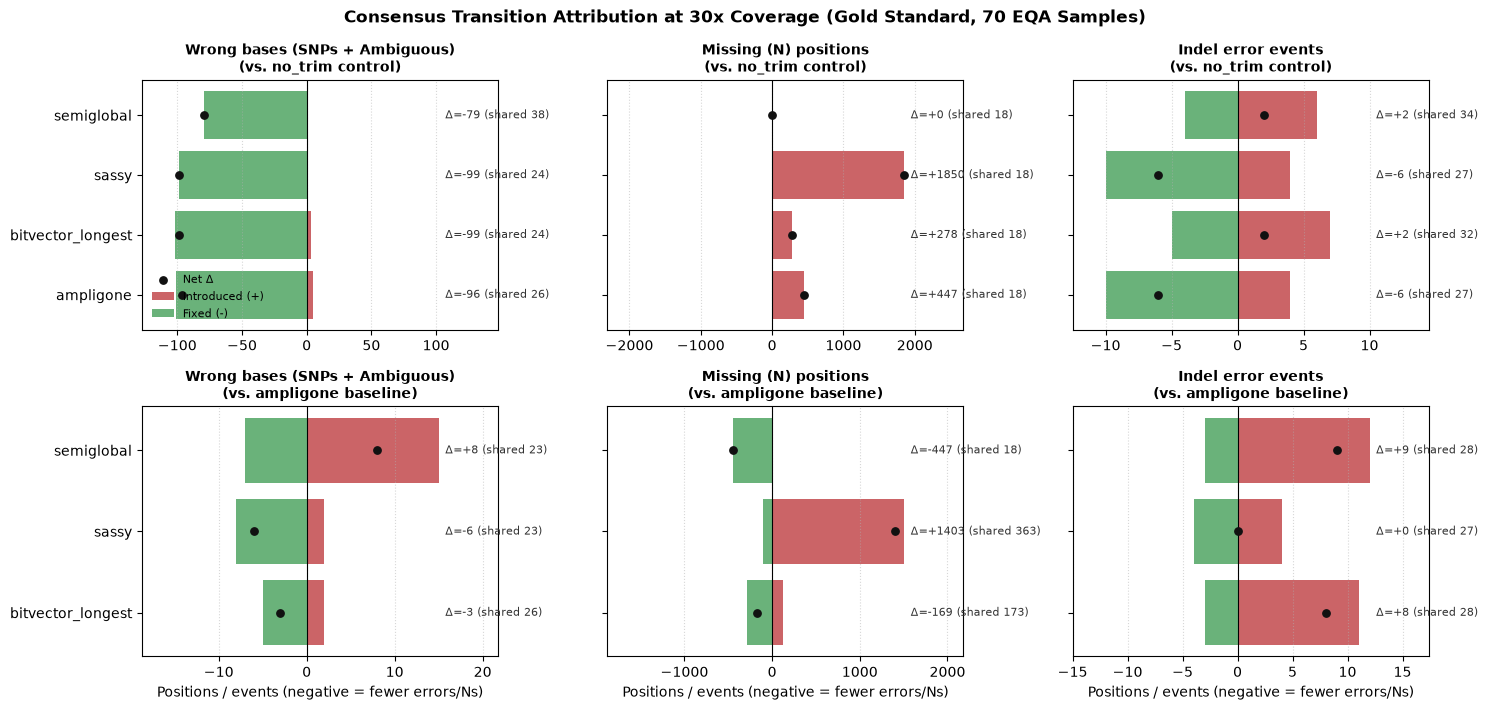

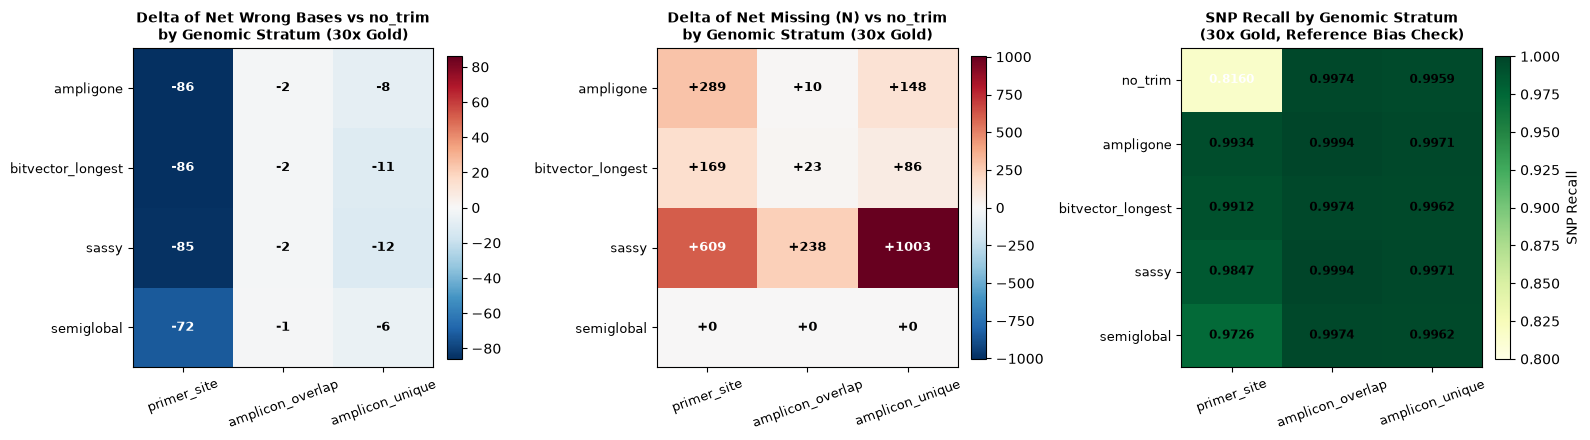

In [12]:
# 1. Attribution Against no_trim Control and Against AmpliGone Baseline (30x Gold)
attr_summary = pd.read_csv(ATTR_SUMMARY_CSV)
attr_summary_amp = pd.read_csv(ATTR_SUMMARY_AMP_CSV)
attr_per_sample = pd.read_csv(ATTR_PER_SAMPLE_CSV)
attr_per_sample_amp = pd.read_csv(ATTR_PER_SAMPLE_AMP_CSV)
attr_by_run = pd.read_csv(ATTR_BY_RUN_CSV)

print("Attribution vs no_trim control (change attributable to primer removal, cov=30, Gold high_cov standard):")
display(
    attr_summary[(attr_summary["standard"] == "gold") & (attr_summary["coverage"] == 30)]
    .set_index("method")
    .round(2)
)

print("\nAttribution vs AmpliGone baseline (sequence-based vs coordinate trimming, cov=30, Gold high_cov standard):")
display(
    attr_summary_amp[(attr_summary_amp["standard"] == "gold") & (attr_summary_amp["coverage"] == 30)]
    .set_index("method")
    .round(2)
)

# --- Figure 1A: Diverging bar charts of Introduced vs Fixed vs Shared (vs no_trim and vs ampligone) ---
gold30_sums = (
    attr_per_sample[(attr_per_sample["standard"] == PRIMARY_STANDARD) & (attr_per_sample["coverage"] == 30)]
    .groupby("method")[[c for c in attr_per_sample.columns if c.endswith(("_introduced", "_fixed", "_shared", "_delta"))]]
    .sum()
    .loc[list(TRIMMERS)]
)
gold30_amp_sums = (
    attr_per_sample_amp[(attr_per_sample_amp["standard"] == PRIMARY_STANDARD) & (attr_per_sample_amp["coverage"] == 30)]
    .groupby("method")[[c for c in attr_per_sample_amp.columns if c.endswith(("_introduced", "_fixed", "_shared", "_delta"))]]
    .sum()
    .loc[list(SEQ_TRIMMERS)]
)

fig, axes = plt.subplots(2, 3, figsize=(15, 7.2), sharey="row")
metrics = (("wrong", "Wrong bases (SNPs + Ambiguous)"), ("missing", "Missing (N) positions"), ("indel", "Indel error events"))

for col, (name, title) in enumerate(metrics):
    # Top row: vs no_trim
    ax = axes[0, col]
    rows = np.arange(len(TRIMMERS))
    intro = gold30_sums[f"{name}_introduced"].to_numpy()
    fixed = gold30_sums[f"{name}_fixed"].to_numpy()
    net = gold30_sums[f"{name}_delta"].to_numpy()
    ax.barh(rows, intro, color="#c44e52", alpha=0.88, label="Introduced (+)")
    ax.barh(rows, -fixed, color="#55a868", alpha=0.88, label="Fixed (-)")
    ax.scatter(net, rows, color="#111111", zorder=5, s=28, label="Net Δ")
    span = max(intro.max(), fixed.max(), 1)
    ax.set_xlim(-span * 1.25, span * 1.45)
    for r, method in enumerate(TRIMMERS):
        shared_val = int(gold30_sums.loc[method, f"{name}_shared"])
        net_val = int(net[r])
        ax.text(span * 1.05, r, f"Δ={net_val:+d} (shared {shared_val})", va="center", fontsize=8, color="#333333")
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"{title}\n(vs. no_trim control)", fontsize=10, fontweight="bold")
    ax.grid(axis="x", linestyle=":", alpha=0.5)

    # Bottom row: vs ampligone
    ax2 = axes[1, col]
    rows2 = np.arange(len(SEQ_TRIMMERS))
    intro2 = gold30_amp_sums[f"{name}_introduced"].to_numpy()
    fixed2 = gold30_amp_sums[f"{name}_fixed"].to_numpy()
    net2 = gold30_amp_sums[f"{name}_delta"].to_numpy()
    ax2.barh(rows2, intro2, color="#c44e52", alpha=0.88, label="Introduced vs AmpliGone (+)")
    ax2.barh(rows2, -fixed2, color="#55a868", alpha=0.88, label="Fixed vs AmpliGone (-)")
    ax2.scatter(net2, rows2, color="#111111", zorder=5, s=28, label="Net Δ")
    span2 = max(intro2.max(), fixed2.max(), 1)
    ax2.set_xlim(-span2 * 1.25, span2 * 1.45)
    for r, method in enumerate(SEQ_TRIMMERS):
        shared_val = int(gold30_amp_sums.loc[method, f"{name}_shared"])
        net_val = int(net2[r])
        ax2.text(span2 * 1.05, r, f"Δ={net_val:+d} (shared {shared_val})", va="center", fontsize=8, color="#333333")
    ax2.axvline(0, color="black", linewidth=0.8)
    ax2.set_title(f"{title}\n(vs. ampligone baseline)", fontsize=10, fontweight="bold")
    ax2.set_xlabel("Positions / events (negative = fewer errors/Ns)")
    ax2.grid(axis="x", linestyle=":", alpha=0.5)

axes[0, 0].set_yticks(np.arange(len(TRIMMERS)), TRIMMERS)
axes[1, 0].set_yticks(np.arange(len(SEQ_TRIMMERS)), SEQ_TRIMMERS)
axes[0, 0].legend(frameon=False, fontsize=8, loc="lower left")
fig.suptitle(f"Consensus Transition Attribution at 30x Coverage (Gold Standard, {len(SAMPLES)} EQA Samples)", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "attribution_f1_introduced_fixed.png", dpi=160, bbox_inches="tight")
plt.show()

# --- Figure 1B: Genomic Stratum Attribution & Stratum Error Heatmap ---
strata_order = ["primer_site", "amplicon_overlap", "amplicon_unique"]
run_gold30 = attr_by_run[
    (attr_by_run["standard"] == PRIMARY_STANDARD)
    & (attr_by_run["coverage"] == 30)
    & (attr_by_run["stratum"].isin(strata_order))
    & (attr_by_run["category"].isin(["introduced", "fixed"]))
    & (attr_by_run["group"].isin(["wrong", "missing"]))
]
stratum_piv = (
    run_gold30.groupby(["method", "stratum", "group", "category"])["positions"]
    .sum()
    .unstack(["group", "category"], fill_value=0)
)
for g in ("wrong", "missing"):
    for cat in ("introduced", "fixed"):
        if (g, cat) not in stratum_piv.columns:
            stratum_piv[(g, cat)] = 0
    stratum_piv[(g, "net_delta")] = stratum_piv[(g, "introduced")] - stratum_piv[(g, "fixed")]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for idx, (g, label) in enumerate((("wrong", "Delta of Net Wrong Bases vs no_trim"), ("missing", "Delta of Net Missing (N) vs no_trim"))):
    mat = stratum_piv[(g, "net_delta")].unstack("stratum", fill_value=0).reindex(index=list(TRIMMERS), columns=strata_order, fill_value=0)
    vmax = max(abs(mat.to_numpy()).max(), 1)
    im = axes[idx].imshow(mat.to_numpy(), cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
    axes[idx].set_xticks(range(len(strata_order)), strata_order, rotation=20, fontsize=9)
    axes[idx].set_yticks(range(len(TRIMMERS)), TRIMMERS, fontsize=9)
    for r in range(mat.shape[0]):
        for c in range(mat.shape[1]):
            val = int(mat.iat[r, c])
            color = "white" if abs(val) > 0.55 * vmax else "black"
            axes[idx].text(c, r, f"{val:+d}", ha="center", va="center", fontsize=9, fontweight="bold", color=color)
    axes[idx].set_title(f"{label}\nby Genomic Stratum (30x Gold)", fontsize=10, fontweight="bold")
    fig.colorbar(im, ax=axes[idx], fraction=0.046, pad=0.04)

if STRATUM_SUMMARY_CSV.is_file():
    stratum_eval = pd.read_csv(STRATUM_SUMMARY_CSV)
    stratum_gold = stratum_eval[(stratum_eval["standard"] == PRIMARY_STANDARD) & (stratum_eval["method"].isin(PRIMER_METHODS))]
    recall_mat = stratum_gold.pivot_table(index="method", columns="stratum", values="snp_recall").reindex(index=list(PRIMER_METHODS), columns=strata_order)
    im3 = axes[2].imshow(recall_mat.to_numpy(), cmap="YlGn", vmin=0.80, vmax=1.0, aspect="auto")
    axes[2].set_xticks(range(len(strata_order)), strata_order, rotation=20, fontsize=9)
    axes[2].set_yticks(range(len(PRIMER_METHODS)), PRIMER_METHODS, fontsize=9)
    for r in range(recall_mat.shape[0]):
        for c in range(recall_mat.shape[1]):
            val = recall_mat.iat[r, c]
            color = "white" if val < 0.88 else "black"
            axes[2].text(c, r, f"{val:.4f}", ha="center", va="center", fontsize=8.5, fontweight="bold", color=color)
    axes[2].set_title("SNP Recall by Genomic Stratum\n(30x Gold, Reference Bias Check)", fontsize=10, fontweight="bold")
    fig.colorbar(im3, ax=axes[2], fraction=0.046, pad=0.04, label="SNP Recall")

fig.tight_layout()
plt.show()

### 2. Per-Sample Attribution Heatmaps (70 EQA Samples)

The heatmaps below show the exact per-sample attributable change (`introduced - fixed`) at `30x` Gold coverage across all 70 samples:
- **Top panels:** Attributable change against `no_trim` for **Wrong bases** (nearly universally negative/blue = primer removal fixes reference bias in primer sites) and **Missing (`N`) positions** (concentrated in a small subset of low-depth samples).
- **Bottom panel:** Attributable change in **Missing (`N`) positions against `ampligone`**, highlighting where `bitvector_longest` and `semiglobal` recover consensus bases that `ampligone` and `sassy` drop below 30x.

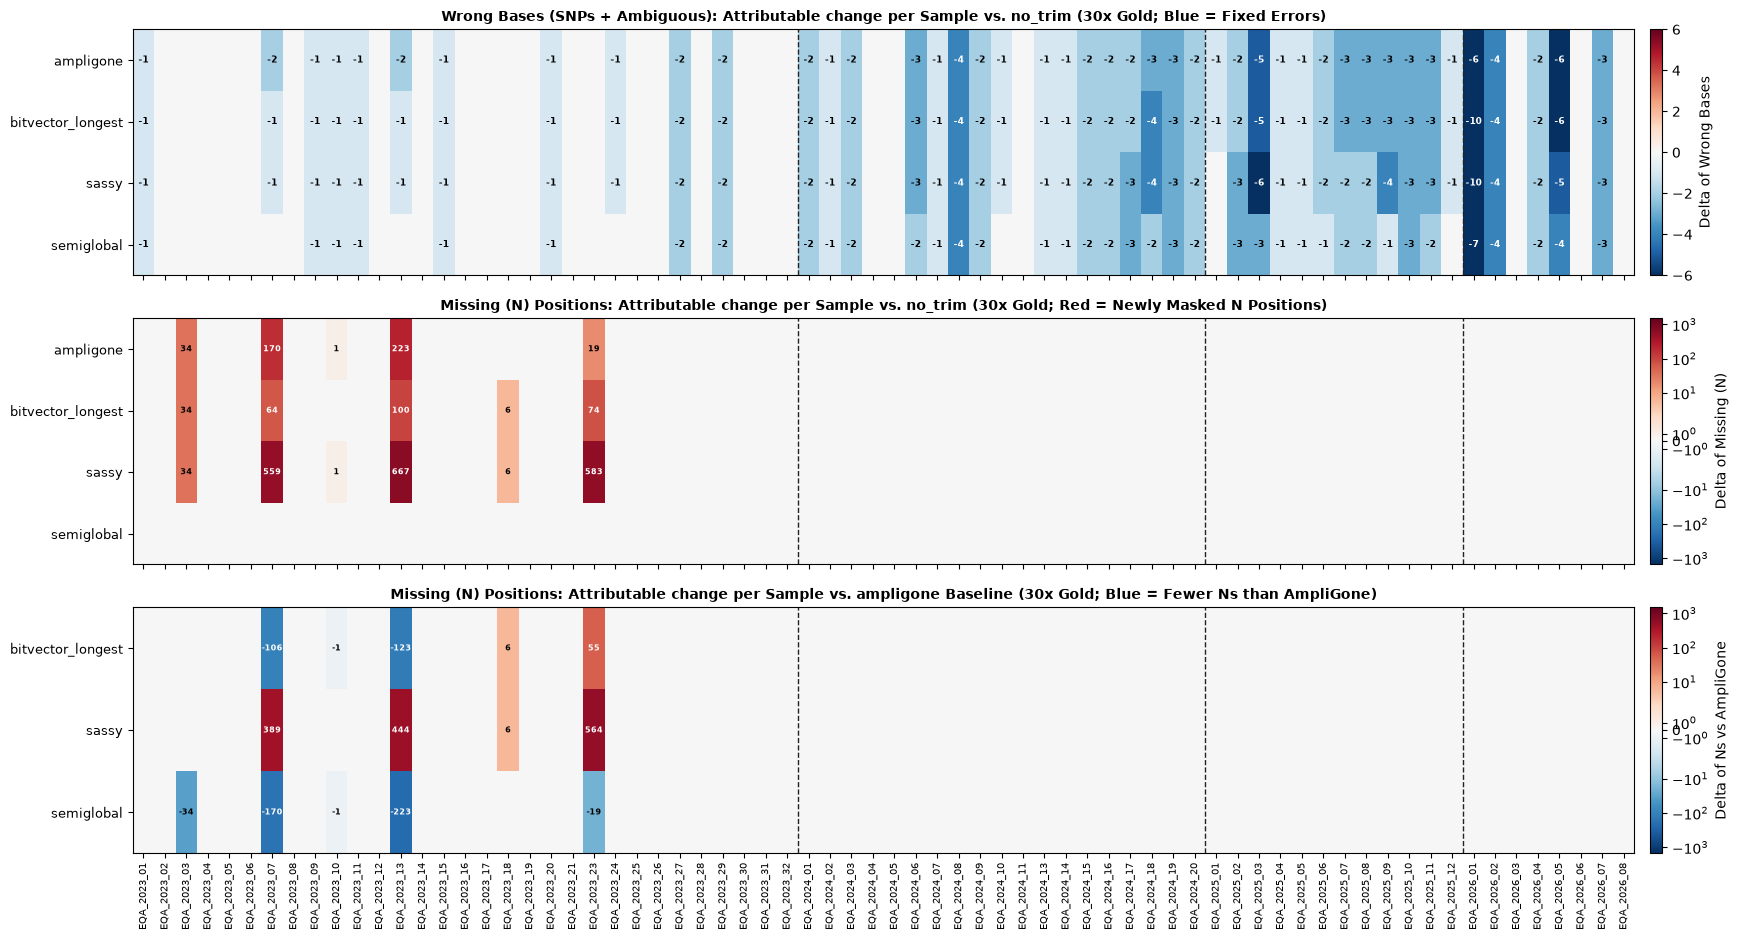

Samples with any attributable change in Missing (N) positions at 30x Gold (6 / 70 samples):


sample,EQA_2023_03,EQA_2023_07,EQA_2023_10,EQA_2023_13,EQA_2023_18,EQA_2023_23
method,,,,,,
ampligone,34,170,1,223,0,19
bitvector_longest,34,64,0,100,6,74
sassy,34,559,1,667,6,583
semiglobal,0,0,0,0,0,0


In [13]:
# 2. Per-Sample Attribution Heatmaps (30x Gold, 70 samples)
fig, axes = plt.subplots(3, 1, figsize=(max(16, 0.25 * len(SAMPLES)), 9.5), sharex=True)

# Panel 1: Wrong bases delta vs no_trim
tbl_wrong = (
    attr_per_sample[(attr_per_sample["standard"] == PRIMARY_STANDARD) & (attr_per_sample["coverage"] == 30)]
    .pivot_table(index="method", columns="sample", values="wrong_delta", aggfunc="sum")
    .reindex(index=list(TRIMMERS))
)
im0 = axes[0].imshow(tbl_wrong.to_numpy(), cmap="RdBu_r", vmin=-6, vmax=6, aspect="auto")
axes[0].set_yticks(range(tbl_wrong.shape[0]), tbl_wrong.index, fontsize=9)
for r in range(tbl_wrong.shape[0]):
    for c in range(tbl_wrong.shape[1]):
        val = int(tbl_wrong.iat[r, c])
        if val != 0:
            axes[0].text(c, r, str(val), ha="center", va="center", fontsize=6.5,
                         color="white" if abs(val) >= 4 else "black", fontweight="bold")
axes[0].set_title("Wrong Bases (SNPs + Ambiguous): Attributable change per Sample vs. no_trim (30x Gold; Blue = Fixed Errors)", fontsize=10, fontweight="bold")
fig.colorbar(im0, ax=axes[0], fraction=0.015, pad=0.01, label="Delta of Wrong Bases")

# Panel 2: Missing (N) positions delta vs no_trim (signed symlog-like color scaling for clarity)
tbl_missing = (
    attr_per_sample[(attr_per_sample["standard"] == PRIMARY_STANDARD) & (attr_per_sample["coverage"] == 30)]
    .pivot_table(index="method", columns="sample", values="missing_delta", aggfunc="sum")
    .reindex(index=list(TRIMMERS))
)
norm_miss = mcolors.SymLogNorm(linthresh=5, linscale=1.0, vmin=-1500, vmax=1500)
im1 = axes[1].imshow(tbl_missing.to_numpy(), cmap="RdBu_r", norm=norm_miss, aspect="auto")
axes[1].set_yticks(range(tbl_missing.shape[0]), tbl_missing.index, fontsize=9)
for r in range(tbl_missing.shape[0]):
    for c in range(tbl_missing.shape[1]):
        val = int(tbl_missing.iat[r, c])
        if val != 0:
            axes[1].text(c, r, str(val), ha="center", va="center", fontsize=6,
                         color="white" if abs(val) >= 50 else "black", fontweight="bold")
axes[1].set_title("Missing (N) Positions: Attributable change per Sample vs. no_trim (30x Gold; Red = Newly Masked N Positions)", fontsize=10, fontweight="bold")
fig.colorbar(im1, ax=axes[1], fraction=0.015, pad=0.01, label="Delta of Missing (N)")

# Panel 3: Missing (N) positions delta vs ampligone
tbl_missing_amp = (
    attr_per_sample_amp[(attr_per_sample_amp["standard"] == PRIMARY_STANDARD) & (attr_per_sample_amp["coverage"] == 30)]
    .pivot_table(index="method", columns="sample", values="missing_delta", aggfunc="sum")
    .reindex(index=list(SEQ_TRIMMERS))
)
im2 = axes[2].imshow(tbl_missing_amp.to_numpy(), cmap="RdBu_r", norm=norm_miss, aspect="auto")
axes[2].set_yticks(range(tbl_missing_amp.shape[0]), tbl_missing_amp.index, fontsize=9)
axes[2].set_xticks(range(tbl_missing_amp.shape[1]), tbl_missing_amp.columns, rotation=90, fontsize=7)
for r in range(tbl_missing_amp.shape[0]):
    for c in range(tbl_missing_amp.shape[1]):
        val = int(tbl_missing_amp.iat[r, c])
        if val != 0:
            axes[2].text(c, r, str(val), ha="center", va="center", fontsize=6,
                         color="white" if abs(val) >= 50 else "black", fontweight="bold")
axes[2].set_title("Missing (N) Positions: Attributable change per Sample vs. ampligone Baseline (30x Gold; Blue = Fewer Ns than AmpliGone)", fontsize=10, fontweight="bold")
fig.colorbar(im2, ax=axes[2], fraction=0.015, pad=0.01, label="Delta of Ns vs AmpliGone")

# Add dataset year boundary lines
sample_years = [SAMPLES[s]["year"] for s in tbl_wrong.columns]
for idx in range(1, len(sample_years)):
    if sample_years[idx] != sample_years[idx - 1]:
        for ax in axes:
            ax.axvline(idx - 0.5, color="#222222", linestyle="--", linewidth=1.0)

fig.tight_layout()
fig.savefig(FIGURE_DIR / "attribution_f6_per_sample.png", dpi=160, bbox_inches="tight")
plt.show()

# Summary table of samples with non-zero missing_delta at 30x Gold
nonzero_miss_cols = tbl_missing.columns[(tbl_missing != 0).any(axis=0)]
print(f"Samples with any attributable change in Missing (N) positions at 30x Gold ({len(nonzero_miss_cols)} / {len(SAMPLES)} samples):")
display(tbl_missing[nonzero_miss_cols])

### 3. Coverage Sweep (`10x`, `30x`, `50x`, `100x`), Trade-offs & Break-Even Analysis

Missing (`N`) positions across coverage thresholds (Gold standard, 70 samples):


coverage,10,30,50,100
method,,,,
no_trim,18,18,1070,24298
ampligone,58,465,2184,31938
bitvector_longest,18,296,1874,29147
sassy,93,1868,5372,37972
semiglobal,18,18,1201,25650



Total errors (`wrong_bases + indel_events`) across coverage thresholds (Gold standard, 70 samples):


coverage,10,30,50,100
method,,,,
no_trim,176,165,159,161
ampligone,71,63,63,63
bitvector_longest,77,67,59,60
sassy,67,56,53,50
semiglobal,88,78,72,73



Break-even exchange rate (bitvector_longest vs comparators; NaN = bitvector_longest dominates on both metrics):


,coverage,comparator,bitvector_wrong_delta,bitvector_missing_delta,comparator_wrong_delta,comparator_missing_delta,missing_per_wrong_base_at_tie
0,10,ampligone,-99,0,-96,31,NaN
1,10,sassy,-99,0,-99,68,NaN
2,10,semiglobal,-99,0,-79,0,NaN
3,30,ampligone,-99,278,-96,447,NaN
4,30,sassy,-99,278,-99,1850,NaN
5,30,semiglobal,-99,278,-79,0,13.90
6,50,ampligone,-99,804,-96,1114,NaN
7,50,sassy,-99,804,-99,4301,NaN
8,50,semiglobal,-99,804,-79,131,33.65
9,100,ampligone,-94,4780,-91,7578,NaN


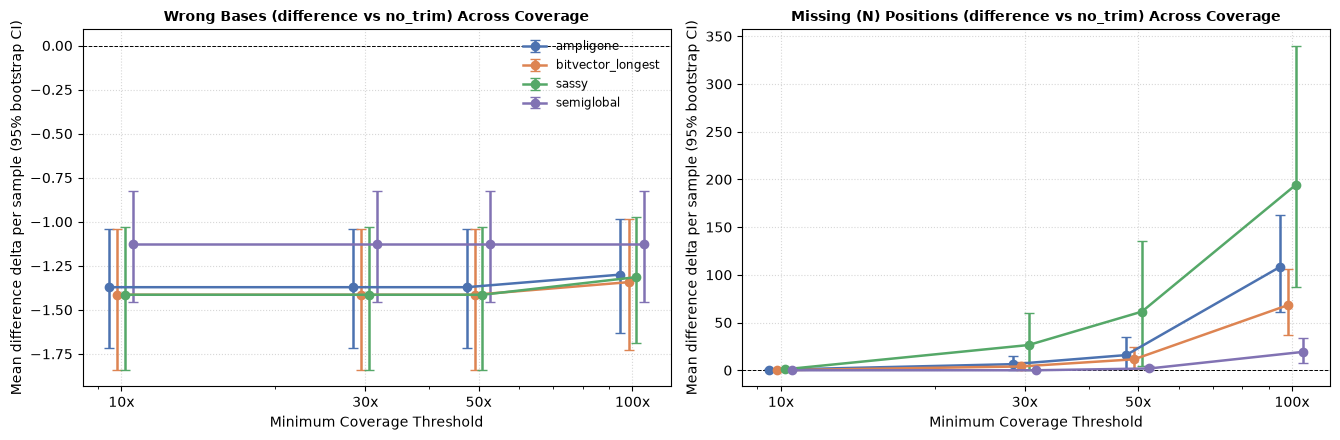

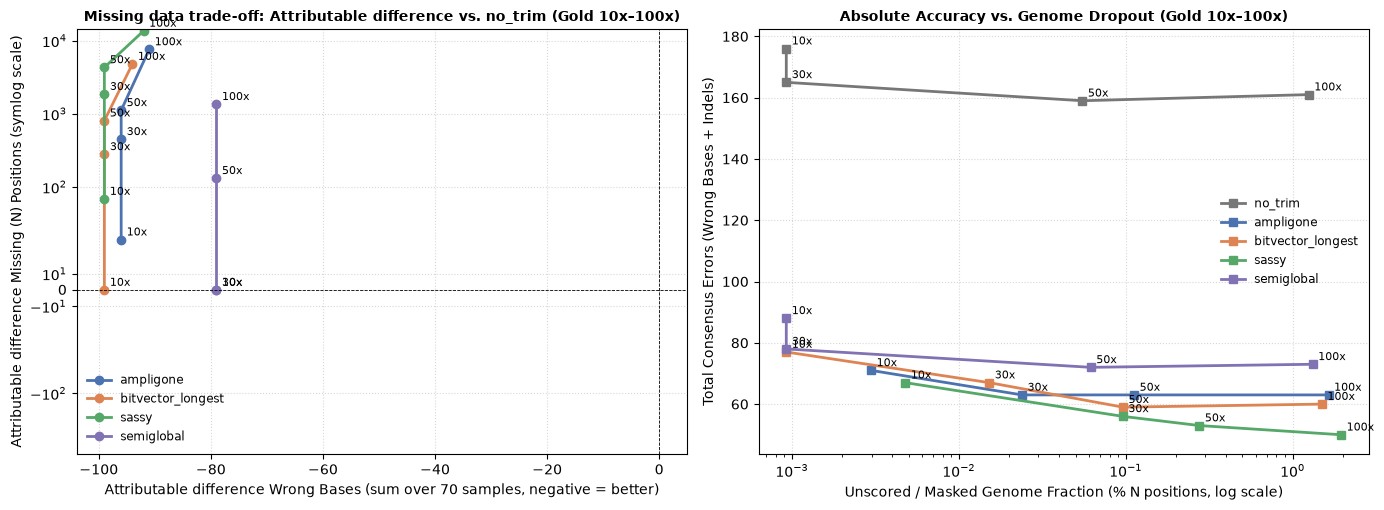

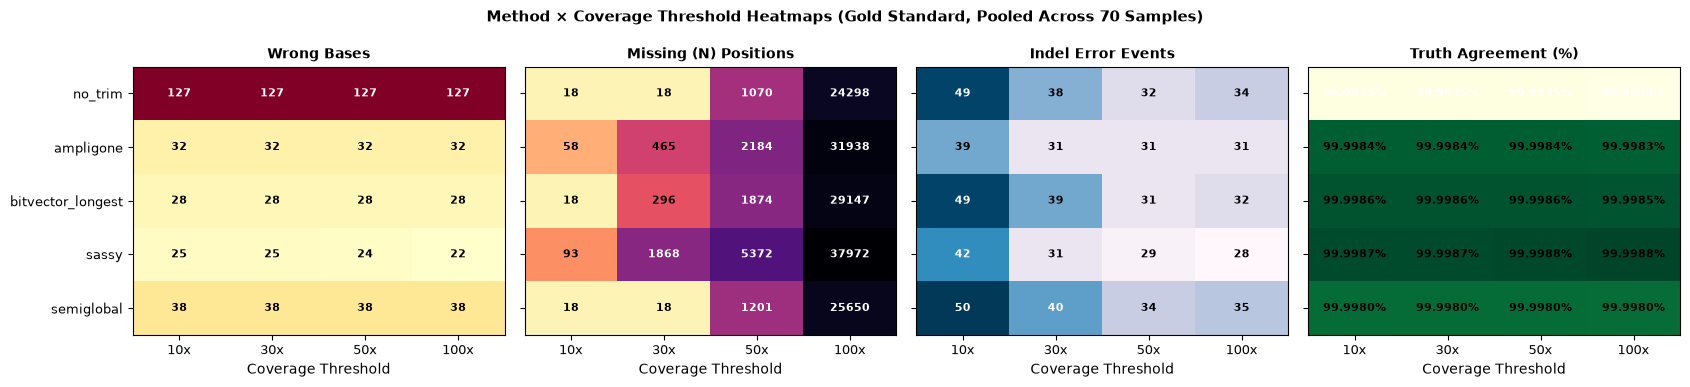

In [14]:
# 3. Coverage Sweep (10x, 30x, 50x, 100x) — Heatmaps, Bootstrap CIs, performance-to-accuracy & Break-Even
coverage_sweep = pd.read_csv(COV_SWEEP_CSV)
gold_sweep = coverage_sweep[coverage_sweep["standard"] == "gold"]
silver_sweep = coverage_sweep[coverage_sweep["standard"] == "silver"]

print("Missing (`N`) positions across coverage thresholds (Gold standard, 70 samples):")
display(gold_sweep.pivot_table(index="method", columns="coverage", values="missing_positions", aggfunc="sum").reindex(list(PRIMER_METHODS)))

print("\nTotal errors (`wrong_bases + indel_events`) across coverage thresholds (Gold standard, 70 samples):")
display(gold_sweep.pivot_table(index="method", columns="coverage", values="total_errors", aggfunc="sum").reindex(list(PRIMER_METHODS)))

if BREAK_EVEN_CSV.is_file():
    break_even = pd.read_csv(BREAK_EVEN_CSV)
    print("\nBreak-even exchange rate (bitvector_longest vs comparators; NaN = bitvector_longest dominates on both metrics):")
    display(break_even.round(2))

# -- Figure 3A: Bootstrap 95% CI Curves of Attributable Delta Across Coverage --
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))
for ax, name, title in zip(axes, ("wrong", "missing"), ("Wrong Bases (difference vs no_trim)", "Missing (N) Positions (difference vs no_trim)")):
    for offset, method in enumerate(TRIMMERS):
        frame = attr_summary[(attr_summary["standard"] == PRIMARY_STANDARD) & (attr_summary["method"] == method)].sort_values("coverage")
        mean = frame[f"{name}_delta_mean"].to_numpy()
        spread = np.clip(np.vstack([mean - frame[f"{name}_delta_low"].to_numpy(), frame[f"{name}_delta_high"].to_numpy() - mean]), 0, None)
        ax.errorbar(frame["coverage"] * (1 + 0.035 * (offset - 1.5)), mean, yerr=spread, marker="o", linewidth=1.8,
                    capsize=3.5, color=COLOURS[method], label=method)
    ax.axhline(0, color="black", linewidth=0.7, linestyle="--")
    ax.set_xscale("log")
    ax.set_xticks(list(ATTR_COVERAGES), [f"{c}x" for c in ATTR_COVERAGES])
    ax.set_xlabel("Minimum Coverage Threshold")
    ax.set_ylabel("Mean difference delta per sample (95% bootstrap CI)")
    ax.set_title(f"{title} Across Coverage", fontsize=10, fontweight="bold")
    ax.grid(True, linestyle=":", alpha=0.5)
axes[0].legend(frameon=False, fontsize=8.5)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "attribution_f2_delta_by_coverage.png", dpi=160, bbox_inches="tight")
plt.show()

# -- Figure 3B: trade-off analysis (Attributable difference delta and Absolute Totals, Gold & Silver) --
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))

# Left: Attributable change vs no_trim (Gold)
for method in TRIMMERS:
    frame = attr_summary[(attr_summary["standard"] == PRIMARY_STANDARD) & (attr_summary["method"] == method)].sort_values("coverage")
    axes[0].plot(frame["wrong_delta_total"], frame["missing_delta_total"], marker="o", linewidth=2, color=COLOURS[method], label=method)
    for _, row in frame.iterrows():
        axes[0].annotate(
            f"{int(row['coverage'])}x",
            (
                row["wrong_delta_total"],
                row["missing_delta_total"]
                ),
            fontsize=8, xytext=(4, 3), textcoords="offset points")
axes[0].axhline(0, color="black", linewidth=0.6, linestyle="--")
axes[0].axvline(0, color="black", linewidth=0.6, linestyle="--")
axes[0].set_yscale("symlog", linthresh=50)
axes[0].set_xlabel("Attributable difference Wrong Bases (sum over 70 samples, negative = better)")
axes[0].set_ylabel("Attributable difference Missing (N) Positions (symlog scale)")
axes[0].set_title("Missing data trade-off: Attributable difference vs. no_trim (Gold 10x–100x)", fontsize=10, fontweight="bold")
axes[0].legend(frameon=False, fontsize=8.5)
axes[0].grid(True, linestyle=":", alpha=0.5)

# Right: Absolute Total Errors vs Completeness (%) across Gold
for method in PRIMER_METHODS:
    grp = gold_sweep[gold_sweep["method"] == method].sort_values("coverage")
    axes[1].plot((1.0 - grp["completeness"]) * 100, grp["total_errors"], marker="s", linewidth=2, color=COLOURS[method], label=method)
    for _, row in grp.iterrows():
        axes[1].annotate(f"{int(row['coverage'])}x", ((1.0 - row["completeness"]) * 100, row["total_errors"]),
                        fontsize=8, xytext=(4, 3), textcoords="offset points")
axes[1].set_xscale("log")
axes[1].set_xlabel("Unscored / Masked Genome Fraction (% N positions, log scale)")
axes[1].set_ylabel("Total Consensus Errors (Wrong Bases + Indels)")
axes[1].set_title("Absolute Accuracy vs. Genome Dropout (Gold 10x–100x)", fontsize=10, fontweight="bold")
axes[1].legend(frameon=False, fontsize=8.5)
axes[1].grid(True, linestyle=":", alpha=0.5)

fig.tight_layout()
fig.savefig(FIGURE_DIR / "attribution_f3_tradeoff_by_coverage.png", dpi=160, bbox_inches="tight")
plt.show()

# -- Figure 3C: Method x Coverage Heatmaps (Wrong Bases, Missing Positions, Indels, Truth Agreement) --
fig, axes = plt.subplots(1, 4, figsize=(17, 3.9), sharey=True)
sweep_specs = [
    ("wrong_bases", "Wrong Bases", "YlOrRd", "{:.0f}", None),
    ("missing_positions", "Missing (N) Positions", "magma_r", "{:.0f}", mcolors.LogNorm(vmin=15, vmax=40000)),
    ("indel_events", "Indel Error Events", "PuBu", "{:.0f}", None),
    ("truth_agreement", "Truth Agreement (%)", "YlGn", "{:.4f}%", None),
]
for ax, (col, title, cmap, fmt, norm) in zip(axes, sweep_specs):
    piv = gold_sweep.pivot_table(index="method", columns="coverage", values=col).reindex(index=list(PRIMER_METHODS), columns=list(ATTR_COVERAGES))
    if col == "truth_agreement":
        piv = piv * 100.0
    im = ax.imshow(piv.to_numpy(), cmap=cmap, norm=norm, aspect="auto")
    ax.set_xticks(range(len(ATTR_COVERAGES)), [f"{c}x" for c in ATTR_COVERAGES], fontsize=9)
    ax.set_xlabel("Coverage Threshold")
    ax.set_title(title, fontsize=10, fontweight="bold")
    vals = piv.to_numpy()
    mid = np.sqrt(vals.min() * vals.max()) if norm is not None else 0.5 * (vals.min() + vals.max())
    for r in range(piv.shape[0]):
        for c in range(piv.shape[1]):
            v = vals[r, c]
            is_dark = (v > mid) if cmap != "YlGn" else (v < mid)
            ax.text(c, r, fmt.format(v), ha="center", va="center", fontsize=8,
                    color="white" if is_dark else "black", fontweight="bold")
axes[0].set_yticks(range(len(PRIMER_METHODS)), PRIMER_METHODS, fontsize=9)
fig.suptitle("Method × Coverage Threshold Heatmaps (Gold Standard, Pooled Across 70 Samples)", fontsize=11, fontweight="bold")
fig.tight_layout()
plt.show()

### 4. Genome-Wide Depth Profile & Amplicon Dropout Heatmaps (`2023`–`2026`)

To understand *why* certain primer trimmers introduce missing (`N`) positions at `30x` coverage, we inspect the per-base coverage depth (`05.cov30.coverage.tsv`) across `MN908947.3` (29,903 nt) and compute the fraction of positions within each amplicon span that drop below `30x` across each EQA dataset year.

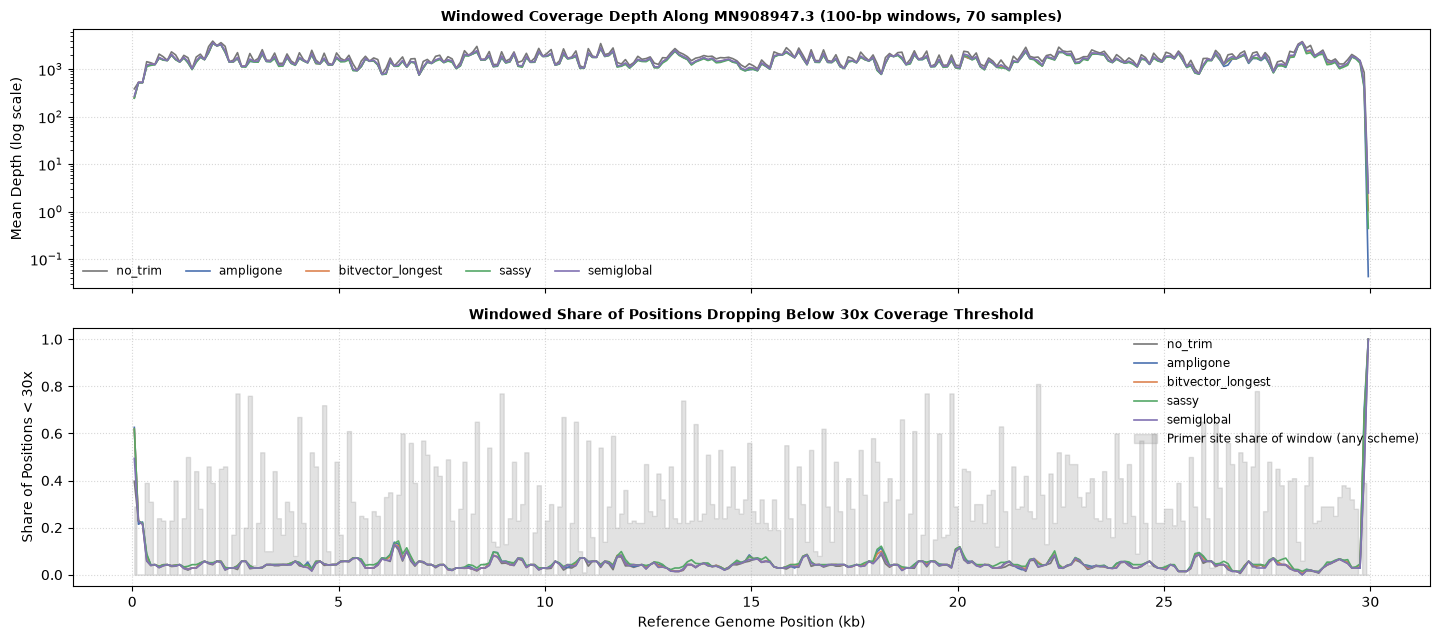

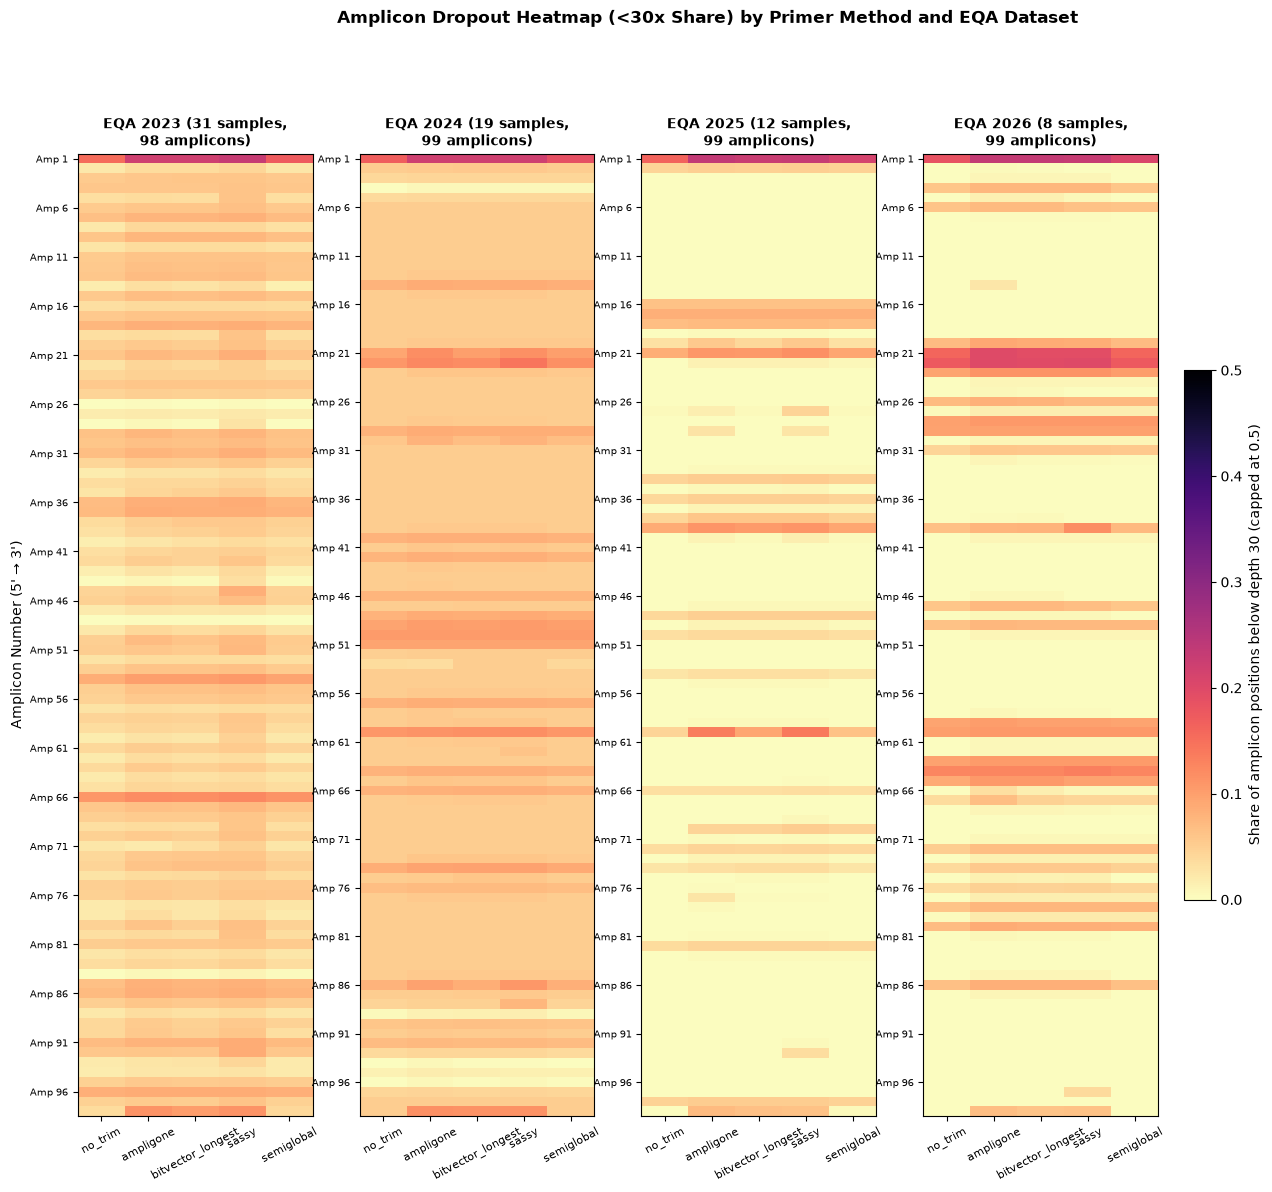

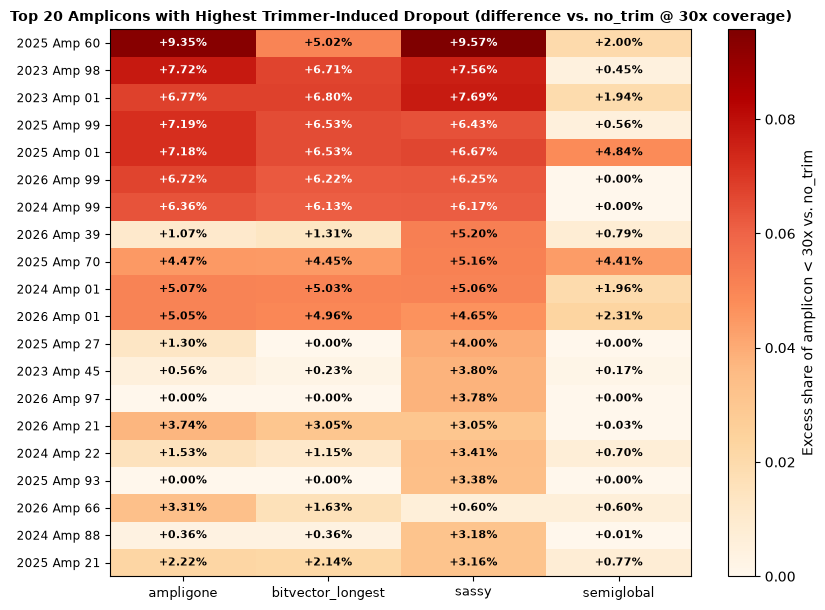

In [15]:
# 4. Genome-Wide Depth Profile & Per-Amplicon Dropout Heatmaps
sample_list = list(SAMPLES.keys())
depth_by_method = {}
for method in PRIMER_METHODS:
    profiles = [
        pd.read_csv(pipeline_paths(sample, method, PIPELINE_DIR, 30)["coverage"], sep="\t", header=None,
                    names=["position", "depth"])["depth"].to_numpy()
        for sample in sample_list
    ]
    depth_by_method[method] = np.vstack(profiles)

# -- Figure 4A: Windowed Genome-Wide Mean Depth & <30x Dropout Share --
WINDOW = 100
edges = np.arange(0, len(REFERENCE_SEQ), WINDOW)
centres = edges + WINDOW / 2
ANY_PRIMER = np.logical_or.reduce([scheme.mask for scheme in SCHEMES.values()])
primer_share = np.array([ANY_PRIMER[start:start + WINDOW].mean() for start in edges])

fig, axes = plt.subplots(2, 1, figsize=(14.5, 6.5), sharex=True)
for method in PRIMER_METHODS:
    depth = depth_by_method[method]
    windowed_depth = np.array([depth.mean(axis=0)[start:start + WINDOW].mean() for start in edges])
    windowed_below = np.array([(depth[:, start:start + WINDOW] < VC_MIN_COVERAGE).mean() for start in edges])
    axes[0].plot(centres / 1000, windowed_depth, color=COLOURS[method], linewidth=1.2, label=method)
    axes[1].plot(centres / 1000, windowed_below, color=COLOURS[method], linewidth=1.2, label=method)

axes[1].fill_between(centres / 1000, 0, primer_share, color="#999999", alpha=0.28, step="mid",
                     label="Primer site share of window (any scheme)")
axes[0].set_yscale("log")
axes[0].set_ylabel("Mean Depth (log scale)")
axes[0].set_title(f"Windowed Coverage Depth Along MN908947.3 (100-bp windows, {len(SAMPLES)} samples)", fontsize=10, fontweight="bold")
axes[0].legend(frameon=False, fontsize=8.5, ncol=5)
axes[0].grid(True, linestyle=":", alpha=0.5)

axes[1].set_ylabel("Share of Positions < 30x")
axes[1].set_xlabel("Reference Genome Position (kb)")
axes[1].set_title("Windowed Share of Positions Dropping Below 30x Coverage Threshold", fontsize=10, fontweight="bold")
axes[1].legend(frameon=False, fontsize=8.5, loc="upper right")
axes[1].grid(True, linestyle=":", alpha=0.5)

fig.tight_layout()
fig.savefig(FIGURE_DIR / "attribution_f5_genome_depth.png", dpi=160, bbox_inches="tight")
plt.show()

# -- Figure 4B: Amplicon Dropout Heatmaps by Dataset Year & Method (Absolute + Delta vs no_trim) --
sample_row = {sample: idx for idx, sample in enumerate(sample_list)}
fig, axes = plt.subplots(1, len(YEARS), figsize=(4.2 * len(YEARS), 12.5))
for ax, year in zip(np.atleast_1d(axes), YEARS):
    scheme = SCHEMES[year]
    rows = [sample_row[s] for s in DATASETS[year]["samples"]]
    amplicons = sorted(scheme.amplicon_spans)
    heat = np.array([
        [(depth_by_method[method][rows, start:end] < VC_MIN_COVERAGE).mean() for method in PRIMER_METHODS]
        for start, end in (scheme.amplicon_spans[a] for a in amplicons)
    ])
    im = ax.imshow(heat, aspect="auto", cmap="magma_r", vmin=0, vmax=0.5)
    ax.set_xticks(range(len(PRIMER_METHODS)), PRIMER_METHODS, rotation=28, fontsize=8)
    ax.set_yticks(range(0, len(amplicons), 5), [f"Amp {amplicons[i]}" for i in range(0, len(amplicons), 5)], fontsize=7.5)
    ax.set_title(f"EQA {year} ({len(rows)} samples,\n{len(amplicons)} amplicons)", fontsize=10, fontweight="bold")
axes[0].set_ylabel("Amplicon Number (5' → 3')")
fig.colorbar(im, ax=axes, label="Share of amplicon positions below depth 30 (capped at 0.5)", shrink=0.55, pad=0.02)
fig.suptitle("Amplicon Dropout Heatmap (<30x Share) by Primer Method and EQA Dataset", fontsize=12, fontweight="bold", y=0.995)
fig.savefig(FIGURE_DIR / "attribution_f5_amplicon_dropout.png", dpi=160, bbox_inches="tight")
plt.show()

# -- Figure 4C: Top Affected Amplicons — Excess Dropout Induced by Trimming (Method minus no_trim)
delta_records = []
for year in YEARS:
    scheme = SCHEMES[year]
    rows = [sample_row[s] for s in DATASETS[year]["samples"]]
    for amp, (start, end) in sorted(scheme.amplicon_spans.items()):
        base_drop = (depth_by_method["no_trim"][rows, start:end] < VC_MIN_COVERAGE).mean()
        row_dict = {"year_amp": f"{year} Amp {amp:02d}", "no_trim_drop": base_drop}
        for m in TRIMMERS:
            row_dict[m] = (depth_by_method[m][rows, start:end] < VC_MIN_COVERAGE).mean() - base_drop
        delta_records.append(row_dict)

delta_amp_df = pd.DataFrame(delta_records).set_index("year_amp")
delta_amp_df["max_excess"] = delta_amp_df[list(TRIMMERS)].max(axis=1)
top_excess = delta_amp_df.sort_values("max_excess", ascending=False).head(20)[list(TRIMMERS)]

fig, ax = plt.subplots(figsize=(8.5, 6.2))
vmax_ex = max(top_excess.to_numpy().max(), 0.01)
im_ex = ax.imshow(top_excess.to_numpy(), cmap="OrRd", vmin=0, vmax=vmax_ex, aspect="auto")
ax.set_xticks(range(len(TRIMMERS)), TRIMMERS, fontsize=9)
ax.set_yticks(range(len(top_excess)), top_excess.index, fontsize=8.5)
for r in range(top_excess.shape[0]):
    for c in range(top_excess.shape[1]):
        val = top_excess.iat[r, c] * 100
        ax.text(c, r, f"+{val:.2f}%", ha="center", va="center", fontsize=8,
                color="white" if top_excess.iat[r, c] > 0.55 * vmax_ex else "black", fontweight="bold")
ax.set_title("Top 20 Amplicons with Highest Trimmer-Induced Dropout (difference vs. no_trim @ 30x coverage)", fontsize=10, fontweight="bold")
fig.colorbar(im_ex, ax=ax, label="Excess share of amplicon < 30x vs. no_trim")
fig.tight_layout()
plt.show()

### 5. Read-Level Trimming Diagnostics & Raw Pileup Support at Newly Missing Sites

relate the consensus-level dropout differences back to read-level trimming behavior (`trim_diagnostics.csv`, `pipeline_status.csv`) and raw BAM pileup support (`raw_support_sites.csv`, `raw_support_summary.csv`).

Read-level primer trimming diagnostics (mean across 70 EQA samples):


,reads,mean_bases_removed,left_cut_over_60,right_cut_over_60,high_cost_share,same_primer_both_ends,no_left_match,no_right_match
method,,,,,,,,
bitvector_longest,142614.129,61.191,0.106,0.149,0.042,0.014,0.050,0.073
sassy,142614.129,75.837,0.119,0.182,0.036,0.013,0.000,0.000
semiglobal,142614.129,40.689,0.000,0.000,NaN,0.007,0.127,0.201


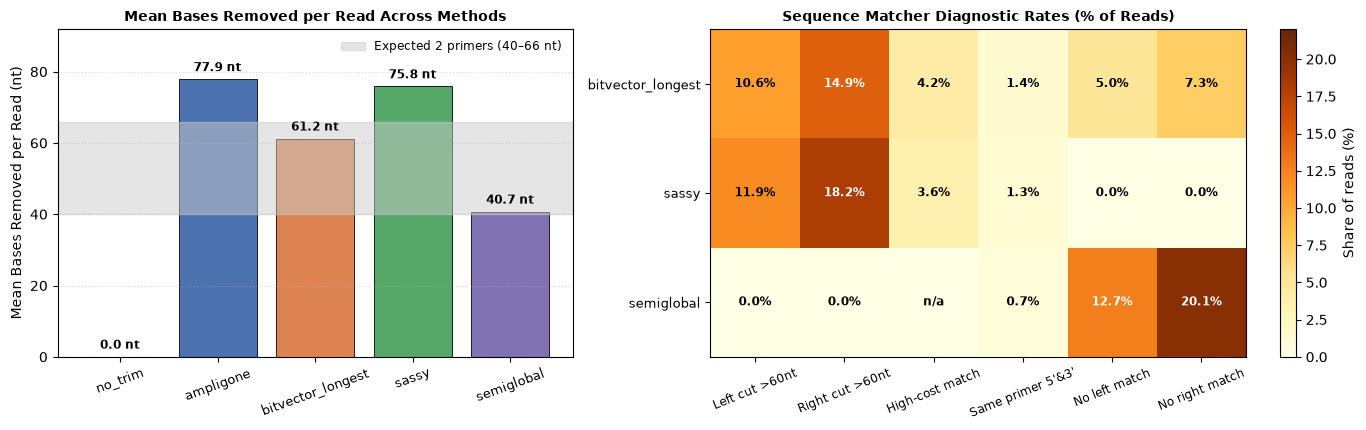

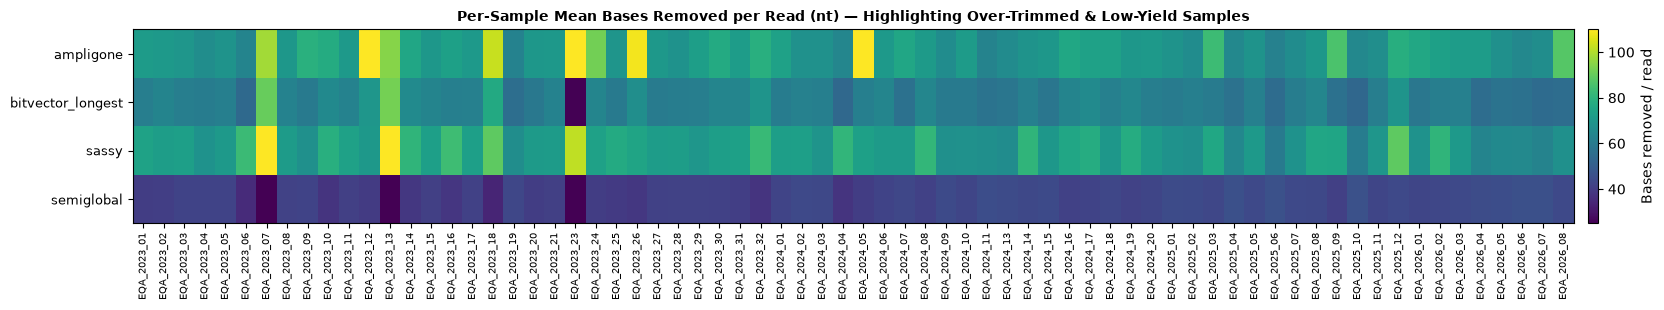


Raw BAM pileup support at non-primer positions newly masked (`N`) or wrong at 30x Gold:


,method,group,kind,sites,median_truth_support,share_majority_truth
0,ampligone,missing,introduced,158,0.991,1.0
1,ampligone,wrong,introduced,1,0.333,0.0
2,ampligone,wrong,shared,7,0.371,0.0
3,bitvector_longest,missing,introduced,109,0.991,1.0
4,bitvector_longest,wrong,shared,4,0.383,0.0
5,sassy,missing,introduced,1241,0.989,1.0
6,sassy,wrong,shared,3,0.376,0.0
7,semiglobal,wrong,shared,10,0.341,0.0


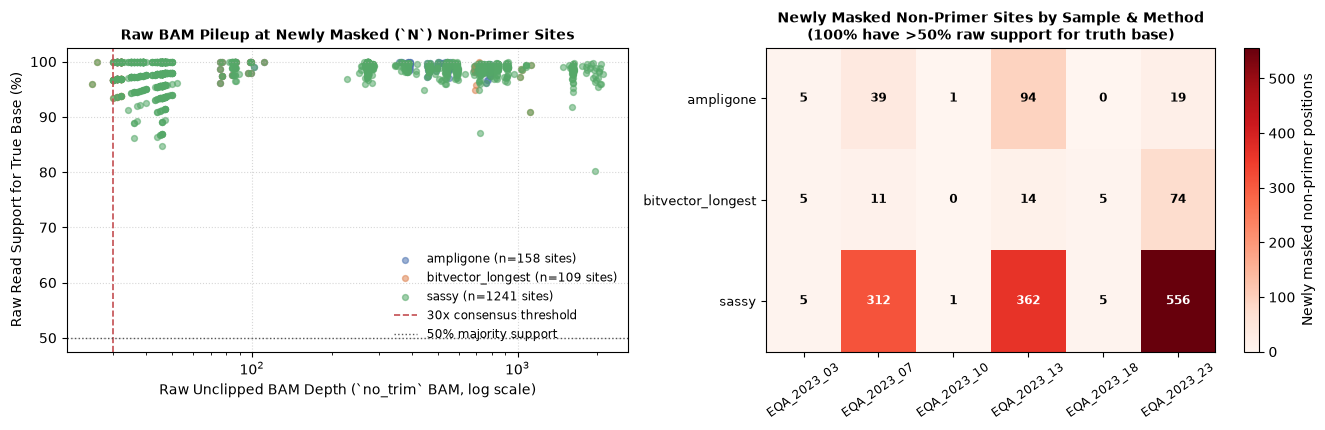

In [16]:
# 5. Read-Level Trimming Diagnostics & Raw BAM Support at Newly Missing Non-Primer Sites
if TRIM_DIAG_CSV.is_file() and PIPELINE_STATUS_CSV.is_file():
    trim_diag = pd.read_csv(TRIM_DIAG_CSV)
    pipe_status = pd.read_csv(PIPELINE_STATUS_CSV)

    print("Read-level primer trimming diagnostics (mean across 70 EQA samples):")
    display(trim_diag.groupby("method").mean(numeric_only=True).round(3))

    # --- Figure 5A: Trimming Diagnostics Summary & Per-Sample Over-Cutting Heatmap ---
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1, 1.3]})

    removed_means = pipe_status.groupby("method")["bases_removed_per_read"].mean().reindex(list(PRIMER_METHODS))
    axes[0].bar(range(len(PRIMER_METHODS)), removed_means.to_numpy(), color=[COLOURS[m] for m in PRIMER_METHODS], edgecolor="black", linewidth=0.6)
    axes[0].axhspan(40, 66, color="#cccccc", alpha=0.5, label="Expected 2 primers (40–66 nt)")
    for idx, val in enumerate(removed_means.to_numpy()):
        axes[0].text(idx, val + 1.5, f"{val:.1f} nt", ha="center", va="bottom", fontsize=8.5, fontweight="bold")
    axes[0].set_xticks(range(len(PRIMER_METHODS)), PRIMER_METHODS, rotation=20, fontsize=9)
    axes[0].set_ylim(0, max(removed_means.max() * 1.18, 85))
    axes[0].set_ylabel("Mean Bases Removed per Read (nt)")
    axes[0].set_title("Mean Bases Removed per Read Across Methods", fontsize=10, fontweight="bold")
    axes[0].legend(frameon=False, fontsize=8.5)
    axes[0].grid(axis="y", linestyle=":", alpha=0.5)

    diag_metrics = ["left_cut_over_60", "right_cut_over_60", "high_cost_share", "same_primer_both_ends", "no_left_match", "no_right_match"]
    diag_mat = trim_diag.groupby("method")[diag_metrics].mean().reindex(list(SEQ_TRIMMERS)) * 100.0
    im_d = axes[1].imshow(diag_mat.fillna(0).to_numpy(), cmap="YlOrBr", vmin=0, vmax=22, aspect="auto")
    axes[1].set_xticks(range(len(diag_metrics)), ["Left cut >60nt", "Right cut >60nt", "High-cost match", "Same primer 5'&3'", "No left match", "No right match"], rotation=22, fontsize=8.5)
    axes[1].set_yticks(range(len(SEQ_TRIMMERS)), SEQ_TRIMMERS, fontsize=9)
    for r in range(diag_mat.shape[0]):
        for c in range(diag_mat.shape[1]):
            v = diag_mat.iat[r, c]
            txt = "n/a" if pd.isna(v) else f"{v:.1f}%"
            color = "white" if (not pd.isna(v) and v > 12) else "black"
            axes[1].text(c, r, txt, ha="center", va="center", fontsize=8.5, fontweight="bold", color=color)
    axes[1].set_title("Sequence Matcher Diagnostic Rates (% of Reads)", fontsize=10, fontweight="bold")
    fig.colorbar(im_d, ax=axes[1], label="Share of reads (%)")
    fig.tight_layout()
    plt.show()

    # Per-sample heatmap of Mean Bases Removed per Read
    fig, ax = plt.subplots(figsize=(max(15, 0.24 * len(SAMPLES)), 3.2))
    rem_piv = pipe_status[pipe_status["sample"].isin(SAMPLES)].pivot_table(index="method", columns="sample", values="bases_removed_per_read").reindex(index=list(TRIMMERS), columns=sample_list)
    im_rem = ax.imshow(rem_piv.to_numpy(), cmap="viridis", vmin=25, vmax=110, aspect="auto")
    ax.set_yticks(range(len(TRIMMERS)), TRIMMERS, fontsize=9)
    ax.set_xticks(range(len(sample_list)), sample_list, rotation=90, fontsize=7)
    ax.set_title("Per-Sample Mean Bases Removed per Read (nt) — Highlighting Over-Trimmed & Low-Yield Samples", fontsize=10, fontweight="bold")
    fig.colorbar(im_rem, ax=ax, fraction=0.015, pad=0.01, label="Bases removed / read")
    fig.tight_layout()
    plt.show()

if RAW_SUPPORT_SUMMARY_CSV.is_file() and RAW_SUPPORT_SITES_CSV.is_file():
    raw_summary = pd.read_csv(RAW_SUPPORT_SUMMARY_CSV)
    raw_sites = pd.read_csv(RAW_SUPPORT_SITES_CSV)
    print("\nRaw BAM pileup support at non-primer positions newly masked (`N`) or wrong at 30x Gold:")
    display(raw_summary.round(4))

    # --- Figure 5B: Raw BAM Depth & Truth Support at Newly Introduced Missing Non-Primer Sites ---
    intro_missing = raw_sites[(raw_sites["group"] == "missing") & (raw_sites["kind"] == "introduced")]
    if not intro_missing.empty:
        fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.4))
        methods_present = [m for m in TRIMMERS if m in set(intro_missing["method"])]

        # Left: Scatter/strip of Raw BAM depth vs Truth allele support
        for m in methods_present:
            sub = intro_missing[intro_missing["method"] == m]
            axes[0].scatter(sub["depth"], sub["truth_support"] * 100, alpha=0.55, s=18, color=COLOURS[m],
                            label=f"{m} (n={len(sub)} sites)")
        axes[0].axvline(30, color="#c44e52", linestyle="--", linewidth=1.2, label="30x consensus threshold")
        axes[0].axhline(50, color="#555555", linestyle=":", linewidth=1.0, label="50% majority support")
        axes[0].set_xscale("log")
        axes[0].set_xlabel("Raw Unclipped BAM Depth (`no_trim` BAM, log scale)")
        axes[0].set_ylabel("Raw Read Support for True Base (%)")
        axes[0].set_title("Raw BAM Pileup at Newly Masked (`N`) Non-Primer Sites", fontsize=10, fontweight="bold")
        axes[0].legend(frameon=False, fontsize=8.5, loc="lower right")
        axes[0].grid(True, linestyle=":", alpha=0.5)

        # Right: Sample-by-Method count of newly introduced non-primer N sites
        site_counts = intro_missing.groupby(["method", "sample"]).size().unstack(fill_value=0).reindex(index=methods_present, fill_value=0)
        im_sc = axes[1].imshow(site_counts.to_numpy(), cmap="Reds", aspect="auto")
        axes[1].set_xticks(range(site_counts.shape[1]), site_counts.columns, rotation=35, fontsize=8.5)
        axes[1].set_yticks(range(site_counts.shape[0]), site_counts.index, fontsize=9)
        vmax_sc = max(site_counts.to_numpy().max(), 1)
        for r in range(site_counts.shape[0]):
            for c in range(site_counts.shape[1]):
                val = int(site_counts.iat[r, c])
                axes[1].text(c, r, str(val), ha="center", va="center", fontsize=8.5, fontweight="bold",
                             color="white" if val > 0.55 * vmax_sc else "black")
        axes[1].set_title("Newly Masked Non-Primer Sites by Sample & Method\n(100% have >50% raw support for truth base)", fontsize=10, fontweight="bold")
        fig.colorbar(im_sc, ax=axes[1], label="Newly masked non-primer positions")
        fig.tight_layout()
        plt.show()